# Predix: demanda e inventario para abarrotes
**3 tiendas · 5 productos básicos · enero 2024 a diciembre 2025**

> **Datos sintéticos.** Se generaron con `predix/generate.py` (semilla fija). Simulan la operación de tres tiendas de abarrotes con la regla de pedido que usa el dueño, por lo que el inventario, los faltantes y la merma salen de esa misma simulación. Las cifras no corresponden a ningún negocio real.

## Resumen ejecutivo

**La regla actual de pedidos ("surtir hasta X piezas lunes y jueves") hace que, en 6 de cada 10 lunes, cada tienda se quede sin leche, pan o huevo antes de cerrar. Al mismo tiempo, tira el 3 % del pan.**

Un pedido calculado con el pronóstico de demanda (`predix`), simulado de julio a diciembre de 2025 con la misma demanda:
- reduce 62 % las unidades que se dejan de vender y 29 % los días con faltantes;
- baja 52 % la merma;
- libera 30 % del capital en inventario.

En total, el **costo de reponer mal** (ventas perdidas, merma y costo de mantener inventario) baja 46 %.

Los tres hallazgos clave:
1. **Las ventas no son la demanda.** Cuando un producto se agota, la venta registrada se queda corta. Un modelo que trata las ventas como demanda sobreestima el efecto del sábado (1.57 contra 1.42 real) y subestima la sensibilidad al precio; el modelo de **demanda censurada** recupera los valores verdaderos.
2. **La quincena y el fin de semana mandan.** Arroz y aceite venden cerca de 25 % más en días de pago, y el sábado vende 41 % más que el lunes.
3. **No todo producto debe tener el mismo nivel de servicio.** En pan conviene agotarse a veces, porque el sobrante caduca; en huevo y abarrote seco conviene no agotarse nunca.

**Contenido:** 1. Datos · 2. Censura · 3. Patrones · 4. Pronóstico · 5. Ventas perdidas · 6. Política de inventario · 7. Recomendaciones

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from predix import inventory as inv, plots
from predix.config import DATA, FIGURES, TRAIN_END
from predix.model import WEEKDAYS, DemandModel, future_frame, quantile, seasonal_naive, wape

pd.set_option("display.float_format", "{:,.2f}".format)
df = pd.read_csv(DATA / "ventas_diarias.csv", parse_dates=["fecha"])
catalog = pd.read_csv(DATA / "catalogo.csv")
df["agotado"] = df["inventario_final"] == 0
FIGURES.mkdir(parents=True, exist_ok=True)
print(f"{len(df):,} registros · {df['tienda'].nunique()} tiendas · {df['producto'].nunique()} productos · "
      f"{df['fecha'].min():%d-%m-%Y} a {df['fecha'].max():%d-%m-%Y}")
df.head()

10,965 registros · 3 tiendas · 5 productos · 01-01-2024 a 31-12-2025


,fecha,tienda,producto,precio_mxn,inventario_inicial,recibido,merma,ventas,inventario_final,pedido,agotado
0,2024-01-01,Tienda A,Leche 1 L,28.00,270,0,0,41,229,41,False
1,2024-01-02,Tienda A,Leche 1 L,28.00,270,41,0,59,211,0,False
2,2024-01-03,Tienda A,Leche 1 L,28.00,211,0,0,51,160,0,False
3,2024-01-04,Tienda A,Leche 1 L,28.00,160,0,0,49,111,159,False
4,2024-01-05,Tienda A,Leche 1 L,28.00,270,159,0,66,204,0,False


## 1. Los datos y el problema

Cada registro es un producto en una tienda en un día. Cuando el inventario final es 0, **la tienda se quedó sin producto**: la venta de ese día es un mínimo, no la demanda real.

In [2]:
summary = df.groupby("producto").agg(dias_agotado=("agotado", "mean"), ventas=("ventas", "sum"), merma=("merma", "sum"))
summary["merma_%_unidades"] = 100 * summary["merma"] / (summary["ventas"] + summary["merma"])
summary["dias_agotado"] *= 100
print("% de días agotado por día de la semana:",
      {WEEKDAYS[d]: round(100 * v, 1) for d, v in df.groupby(df["fecha"].dt.dayofweek)["agotado"].mean().items()})
basics = df[df["producto"].isin(["Leche 1 L", "Pan de caja", "Huevo 1 kg"]) & (df["fecha"].dt.dayofweek == 0)]
print(f"Lunes en que la tienda se queda sin leche, pan o huevo: {basics.groupby(['fecha', 'tienda'])['agotado'].any().mean():.0%}")
summary.rename(columns={"dias_agotado": "% días agotado"})

% de días agotado por día de la semana: {'lun': 19.4, 'mar': 0.0, 'mié': 0.0, 'jue': 0.2, 'vie': 0.0, 'sáb': 0.0, 'dom': 2.8}
Lunes en que la tienda se queda sin leche, pan o huevo: 63%


,% días agotado,ventas,merma,merma_%_unidades
producto,,,,
Aceite 1 L,0.00,30086,0,0.00
Arroz 1 kg,0.00,40060,0,0.00
Huevo 1 kg,4.01,86271,0,0.00
Leche 1 L,6.48,129122,22,0.02
Pan de caja,5.61,70993,2160,2.95


Los faltantes se concentran en **lunes y domingo**: el pedido del jueves no alcanza para el fin de semana. A la vez, parte del pan de la entrega del martes caduca antes de venderse: la tienda tiene **faltantes y merma al mismo tiempo**.

## 2. Medir la demanda cuando hay faltantes: el modelo censurado

La demanda diaria se modela como binomial negativa (conteos con sobredispersión), con estas variables:
- nivel por tienda y producto;
- día de la semana y fin de semana de la Tienda C;
- quincena por producto y diciembre;
- tendencia por tienda;
- elasticidad precio por producto.

Los días agotados no aportan "venta = demanda", sino **P(demanda ≥ venta)**: es una verosimilitud censurada, como un modelo Tobit para conteos.

Se comparan tres formas de estimar el modelo, entrenadas con enero 2024 a junio 2025. Como los datos son simulados, conocemos los valores reales y podemos medir el sesgo de cada método.

In [3]:
train = df[df["fecha"] <= TRAIN_END].reset_index(drop=True)
test = df[df["fecha"] > TRAIN_END].reset_index(drop=True)
models = {"Ventas como demanda": DemandModel(censored=False).fit(train),
          "Excluyendo días agotados": DemandModel(censored=False, drop_stockouts=True).fit(train),
          "Demanda censurada": DemandModel().fit(train)}
rows = {"día sáb": 1.25 / 0.88, "día dom": 1.10 / 0.88, "quincena · Huevo 1 kg": 1.15,
        "quincena · Arroz 1 kg": 1.30, "diciembre": 1.12}
check = pd.DataFrame({name: m.effects()[list(rows)] for name, m in models.items()})
check.insert(0, "Valor real (simulación)", pd.Series(rows))
elasticity = {name: np.log(m.effects()["log precio · Huevo 1 kg"]) for name, m in models.items()}
check.loc["elasticidad precio · Huevo"] = [-0.6] + list(elasticity.values())
check.round(3)

,Valor real (simulación),Ventas como demanda,Excluyendo días agotados,Demanda censurada
día sáb,1.42,1.57,1.46,1.41
día dom,1.25,1.40,1.29,1.26
quincena · Huevo 1 kg,1.15,1.15,1.15,1.15
quincena · Arroz 1 kg,1.30,1.25,1.24,1.24
diciembre,1.12,1.10,1.11,1.12
elasticidad precio · Huevo,-0.60,-0.50,-0.60,-0.60


Tratar las ventas como demanda **infla el efecto del sábado de 1.42 a 1.57**: el lunes parece flojo porque no había producto, no porque falten clientes. También subestima la elasticidad del huevo. Excluir los días agotados ayuda, pero deja un sesgo, porque se descartan justo los días de mayor demanda. El modelo censurado recupera los valores reales.

Con el modelo censurado entrenado con todo el periodo se compara la venta registrada contra la demanda estimada por día de la semana:

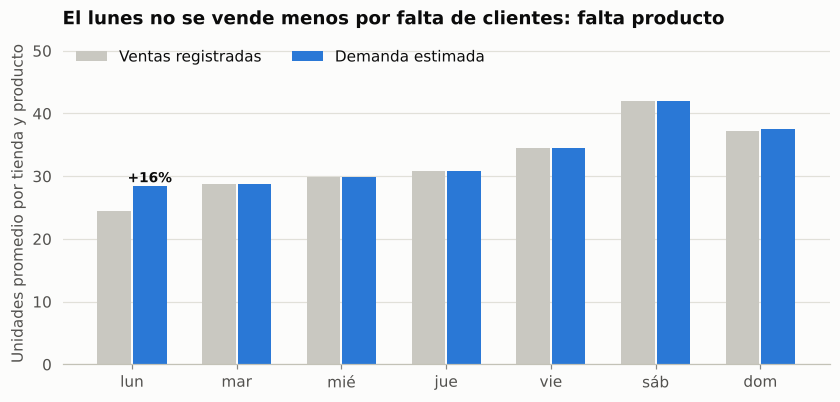

In [4]:
model = DemandModel().fit(df)
df["demanda_estimada"] = inv.estimated_demand(df, model)
by_day = df.groupby(df["fecha"].dt.dayofweek)[["ventas", "demanda_estimada"]].mean()
by_day.index = [WEEKDAYS[d] for d in by_day.index]
by_day.columns = ["ventas", "demanda"]
fig = plots.ventas_vs_demanda(by_day)
fig.savefig(FIGURES / "ventas_vs_demanda.png")

## 3. Patrones de demanda

Efectos multiplicativos del modelo censurado. Por ejemplo, 1.30 significa 30 % más demanda:

In [5]:
effects = model.effects()
patterns = pd.DataFrame({"efecto": effects})
patterns["grupo"] = patterns.index.str.split(" ").str[0]
elastic = np.log(effects[effects.index.str.startswith("log precio")])
print("Elasticidades precio:", elastic.round(2).to_dict())
patterns.loc[~patterns.index.str.startswith("log precio"), ["efecto"]].round(3)

Elasticidades precio: {'log precio · Aceite 1 L': -1.15, 'log precio · Arroz 1 kg': -0.46, 'log precio · Huevo 1 kg': -0.59, 'log precio · Leche 1 L': -0.39, 'log precio · Pan de caja': -0.47}


,efecto
día mar,1.01
día mié,1.06
día jue,1.09
día vie,1.22
día sáb,1.40
día dom,1.25
fin de semana · Tienda C,1.15
quincena · Aceite 1 L,1.32
quincena · Arroz 1 kg,1.25
quincena · Huevo 1 kg,1.14


Lectura:
- **Día de la semana:** el sábado vende 41 % más que el lunes, y la Tienda C (cerca del mercado) tiene un fin de semana todavía más fuerte.
- **Quincena:** arroz y aceite se compran por despensa en días de pago (≈ +25 %); leche y pan casi no cambian.
- **Precio:** el aceite es muy sensible a la promoción mensual (elasticidad ≈ −1.1), y el alza del huevo de marzo de 2025 redujo su demanda (≈ −0.6).
- **Tendencia:** la Tienda B crece cerca de 12 % al año, pero la regla de pedido no se ha ajustado.

## 4. Pronóstico: prueba fuera de muestra

Se pronostica julio a diciembre de 2025 sin usar esos datos para entrenar. La comparación es contra dos métodos comunes en tiendas: el mismo día de la semana pasada y el promedio de las últimas 4 semanas. Se evalúa solo en días **sin** faltante, donde la venta sí es la demanda.
- **WAPE:** error absoluto ponderado (menor es mejor).
- **Sesgo:** negativo significa que el método pronostica de menos.

In [6]:
full = df.copy()
full["Mismo día semana pasada"] = seasonal_naive(full, (7,))
full["Promedio 4 semanas"] = seasonal_naive(full, (7, 14, 21, 28))
evaluation = full[full["fecha"] > TRAIN_END].copy()
evaluation["Binomial negativa (ventas como demanda)"] = models["Ventas como demanda"].predict(evaluation).to_numpy()
evaluation["Binomial negativa censurada"] = models["Demanda censurada"].predict(evaluation).to_numpy()
ok = ~evaluation["agotado"]
methods = ["Mismo día semana pasada", "Promedio 4 semanas", "Binomial negativa (ventas como demanda)",
           "Binomial negativa censurada"]
pd.DataFrame({"WAPE": [wape(evaluation.loc[ok, "ventas"], evaluation.loc[ok, m]) for m in methods],
              "sesgo": [(evaluation.loc[ok, m] - evaluation.loc[ok, "ventas"]).sum() / evaluation.loc[ok, "ventas"].sum()
                        for m in methods]}, index=methods).style.format("{:.1%}")

,WAPE,sesgo
Mismo día semana pasada,31.7%,-0.7%
Promedio 4 semanas,25.4%,-1.6%
Binomial negativa (ventas como demanda),22.3%,-2.3%
Binomial negativa censurada,22.1%,-0.3%


El modelo censurado tiene el menor error y prácticamente cero sesgo. El error restante, cerca de 22 %, es en buena parte ruido diario irreducible: con 30 a 60 piezas al día la demanda varía ±25 % aunque nada cambie. Lo que no tiene es sesgo, que es lo que llena o vacía el anaquel.

Pronóstico de las próximas dos semanas para un producto (el intervalo de 80 % es el que se usa para decidir cuánto pedir):

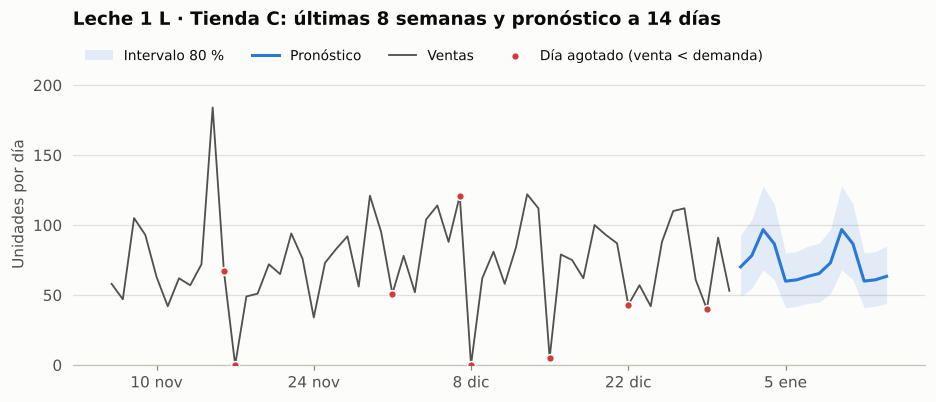

In [7]:
sku = ("Tienda C", "Leche 1 L")
hist = df[(df["tienda"] == sku[0]) & (df["producto"] == sku[1])].tail(56)
future = future_frame(df, 14)
future = future[(future["tienda"] == sku[0]) & (future["producto"] == sku[1])].reset_index(drop=True)
future["mu"] = model.predict(future).to_numpy()
future["p10"], future["p90"] = quantile(model, future["mu"], 0.10), quantile(model, future["mu"], 0.90)
fig = plots.pronostico(hist, future, f"{sku[1]} · {sku[0]}: últimas 8 semanas y pronóstico a 14 días")
fig.savefig(FIGURES / "pronostico_leche_tienda_c.png")

## 5. ¿Cuánto se deja de vender?

En cada día agotado, la demanda estimada es E[D | D ≥ venta]. Con datos reales no se puede comprobar, pero aquí la demanda verdadera es conocida, así que se valida la estimación del segundo semestre de 2025:

In [8]:
from predix.generate import generate

lost = df.assign(perdidas=df["demanda_estimada"] - df["ventas"])
lost["margen_perdido"] = lost["perdidas"] * lost["precio_mxn"] * (1 - lost["producto"].map(catalog.set_index("producto")["costo_sobre_precio"]))
print(lost.groupby("producto")[["perdidas", "margen_perdido"]].sum().round(0))

truth = generate()["demanda_real"]
h2 = test.merge(truth, on=["fecha", "tienda", "producto"])
estimated = (inv.estimated_demand(h2, models["Demanda censurada"]) - h2["ventas"]).sum()
real = (h2["demanda_real"] - h2["ventas"]).sum()
print(f"\nJul–dic 2025 · unidades perdidas estimadas: {estimated:,.0f} · reales: {real:,.0f} ({estimated / real - 1:+.1%})")

             perdidas  margen_perdido
producto                             
Aceite 1 L       0.00            0.00
Arroz 1 kg       0.00            0.00
Huevo 1 kg   1,451.00       13,128.00
Leche 1 L    3,713.00       21,871.00
Pan de caja  1,608.00       24,207.00

Jul–dic 2025 · unidades perdidas estimadas: 2,195 · reales: 2,339 (-6.2%)


La estimación queda a 6 % de las ventas perdidas reales, y es ligeramente conservadora. Leche, huevo y pan concentran todo lo que se deja de vender.

## 6. Política de inventario: nivel objetivo con pronóstico

**Regla actual** (deducida de los pedidos): los lunes y jueves se pide hasta un nivel fijo por producto y tienda.

**Propuesta:** en cada día de pedido, el nivel objetivo es la demanda pronosticada hasta la siguiente entrega más un colchón de seguridad. El colchón se calcula con la varianza de la binomial negativa y un **nivel de servicio** propio de cada producto.

El nivel de servicio se elige por simulación con los datos de entrenamiento (enero 2024 a junio 2025), maximizando la utilidad. La utilidad descuenta tres cosas del margen:
- **merma** a costo;
- **ventas perdidas**;
- **costo de mantener inventario**, 25 % anual.

Nivel de servicio elegido:
         Aceite 1 L Arroz 1 kg Huevo 1 kg Leche 1 L Pan de caja
Tienda A        98%        98%        98%       90%         70%
Tienda B        98%        98%        98%       90%         70%
Tienda C        98%        98%        98%       95%         70%


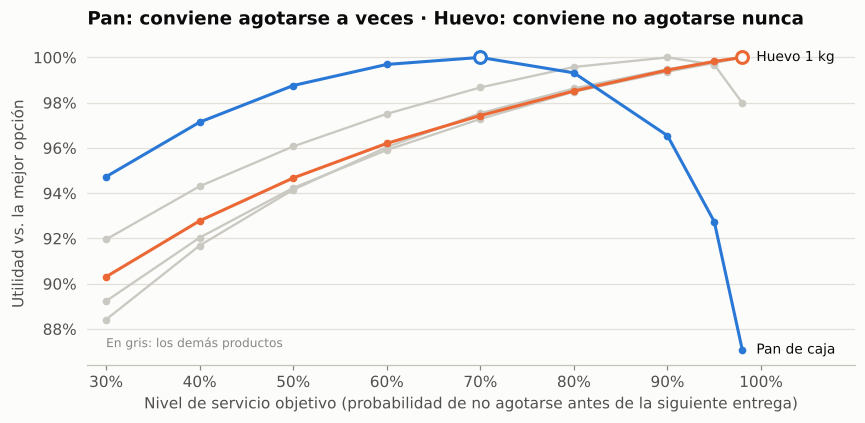

In [9]:
best, grid = inv.tune_service_levels(train, models["Demanda censurada"], catalog)
print("Nivel de servicio elegido:")
print(pd.Series(best).unstack().map("{:.0%}".format))
curves = grid.groupby(["nivel_servicio", "producto"])["utilidad_mxn"].sum().unstack()
curves = curves / curves.max()
fig = plots.utilidad_por_servicio(curves, highlight=["Pan de caja", "Huevo 1 kg"])
fig.savefig(FIGURES / "utilidad_por_nivel_de_servicio.png")

Es el clásico **problema del vendedor de periódicos** (*newsvendor*). Si todo el sobrante se tirara, el nivel de servicio óptimo sería margen / (margen + costo), que en el pan da 30 %. Como parte del sobrante alcanza a venderse antes de caducar, el óptimo del pan sube a 70 %; aun así, conviene agotarse a veces. En el huevo, el arroz y el aceite el sobrante no se pierde, y conviene cubrir casi siempre la demanda (98 %).

**Prueba fuera de muestra** (julio a diciembre 2025): las dos políticas se simulan con la misma demanda estimada.

Costo de reponer mal: 42,119 → 22,826 MXN (-46%) · utilidad del semestre +19,293 MXN


politica,Regla actual,Propuesta,cambio
dias_con_quiebre,104,74,-29%
unidades_perdidas,"2,195",831,-62%
margen_perdido_mxn,"18,739","10,249",-45%
merma_mxn,"17,109","8,171",-52%
inventario_promedio_mxn,"49,756","34,959",-30%
costo_reposicion_mxn,"42,119","22,826",-46%
utilidad_mxn,"851,376","870,669",+2%


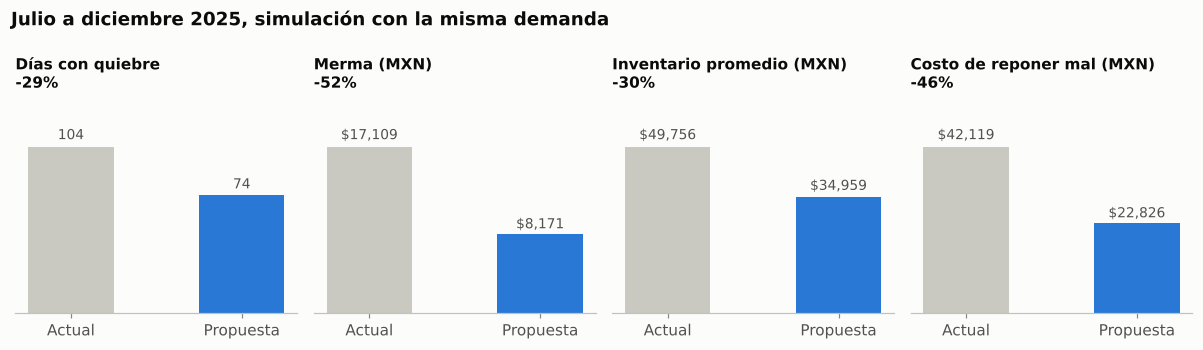

In [10]:
results = inv.compare_policies(test, models["Demanda censurada"], catalog, service_by_sku=best)
cols = ["dias_con_quiebre", "unidades_perdidas", "margen_perdido_mxn", "merma_mxn", "inventario_promedio_mxn",
        "costo_reposicion_mxn", "utilidad_mxn"]
total = results.groupby("politica")[cols].sum().loc[["Regla actual", "Propuesta"]]
fig = plots.comparacion_politicas(total)
fig.savefig(FIGURES / "comparacion_politicas.png")
delta = total.loc["Propuesta"] - total.loc["Regla actual"]
print(f"Costo de reponer mal: {total.loc['Regla actual', 'costo_reposicion_mxn']:,.0f} → {total.loc['Propuesta', 'costo_reposicion_mxn']:,.0f} MXN "
      f"({delta['costo_reposicion_mxn'] / total.loc['Regla actual', 'costo_reposicion_mxn']:+.0%}) · utilidad del semestre {delta['utilidad_mxn']:+,.0f} MXN")
total.T.assign(cambio=lambda t: t["Propuesta"] / t["Regla actual"] - 1).style.format("{:,.0f}").format("{:+.0%}", subset=["cambio"])

In [11]:
by_product = results.pivot_table(index="producto", columns="politica", values=["dias_con_quiebre", "merma_mxn", "inventario_promedio_mxn"], aggfunc="sum")
by_product.round(0)

dias_con_quiebre              inventario_promedio_mxn  \
politica           Propuesta Regla actual               Propuesta   
producto                                                            
Aceite 1 L                 4            0                3,900.00   
Arroz 1 kg                 6            0                3,854.00   
Huevo 1 kg                 6           21               12,190.00   
Leche 1 L                 16           47                8,895.00   
Pan de caja               42           36                6,120.00   

                         merma_mxn               
politica    Regla actual Propuesta Regla actual  
producto                                         
Aceite 1 L      9,387.00      0.00         0.00  
Arroz 1 kg      8,998.00      0.00         0.00  
Huevo 1 kg     14,032.00      0.00         0.00  
Leche 1 L       9,109.00    838.00        48.00  
Pan de caja     8,230.00  7,333.00    17,061.00

## 7. Recomendaciones

1. **Pedir con nivel objetivo dinámico.** El objetivo de cada lunes y jueves debe cubrir los días hasta la siguiente entrega, con más volumen antes del fin de semana y de la quincena. Esto reduce 62 % las ventas perdidas y 52 % la merma, con 30 % menos capital en inventario.
2. **Un nivel de servicio por tipo de producto.** Alto (98 %) para no perecederos y huevo, 90–95 % para leche y ≈ 70 % para pan, donde el sobrante caduca. Si el pan pudiera recibirse más seguido, por ejemplo con entrega diaria, convendría subirlo.
3. **Ajustar la Tienda B a su crecimiento** (~12 % al año). La regla fija no lo considera y sus faltantes crecen año con año.
4. **Medir la demanda, no solo la venta.** Basta registrar a qué hora se agota cada producto. Mejoraría el pronóstico y permitiría cuantificar las ventas perdidas sin modelo.

## Limitaciones

- **Datos simulados:** una tienda real tiene más productos, promociones cruzadas y proveedores con entregas variables.
- **Ventas perdidas:** la simulación asume que se pierden, sin que el cliente sustituya por otra marca. Si sustituye, el beneficio real es menor.
- **Costo de inventario:** el 25 % anual es un supuesto razonable para un negocio pequeño, pero conviene revisarlo.